# Demo: flujo de delegación del orquestador multi-agente

Tres consultas reales contra Gemini y Pinecone, para ver al **Supervisor** decidir en cada turno
a quién delegar, con qué instrucción y por qué:

1. **Delegación completa** — la pregunta necesita un dato de las políticas *y* una cuenta.
2. **Un solo dominio** — la pregunta no necesita cálculo: el supervisor no llama al analista.
3. **Camino de fallo** — el investigador falla (falla inyectada) y el supervisor se recupera.

Requisito: el índice cargado (`python scripts/setup_indice.py` y `python scripts/ingestar.py`)
y un `.env` con `GOOGLE_API_KEY` y `PINECONE_API_KEY`.

In [1]:
from IPython.display import Image, Markdown, display

from agents.llm import MODELO
from graph import app
from main import PREGUNTA_DEMO, correr_consulta
from rag.config import INDEX_NAME, NAMESPACE

print(f"Modelo: {MODELO} · Índice: {INDEX_NAME} / {NAMESPACE}")

Modelo: gemini-flash-lite-latest · Índice: techcorp-politicas / politicas-internas


In [2]:
def tabla_de_decisiones(traza: dict) -> None:
    """Las decisiones del supervisor y la validez de cada aporte, como tabla."""
    filas = ["| Turno | Supervisor decide | Razón |", "|---|---|---|"]
    for d in traza["decisiones"]:
        filas.append(f"| {d['turno']} | **{d['next']}** | {d['razon']} |")
    filas += ["", "| Especialista | Validación | Herramientas |", "|---|---|---|"]
    for c in traza["contribuciones"]:
        marca = "✅ válida" if c["valido"] else f"❌ {c['motivo']}"
        filas.append(f"| {c['agente']} | {marca} | {', '.join(c['herramientas_usadas']) or '—'} |")
    display(Markdown("\n".join(filas)))

## El grafo

Topología jerárquica: el supervisor es el único nodo con aristas condicionales (punteadas). Los
especialistas siempre vuelven a él y nunca hablan entre sí; solo la síntesis llega a `END`.

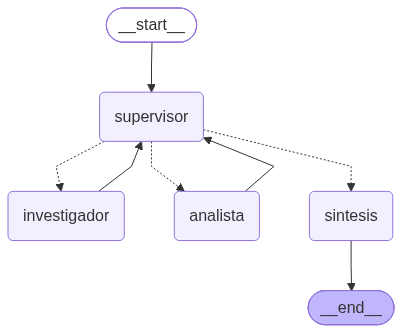

In [3]:
display(Image(app.get_graph().draw_mermaid_png()))

## 1. Delegación completa

La pregunta **no trae los números**: los días por antigüedad solo están en las políticas. El
supervisor tiene que mandar a buscar, recibir el dato, pasárselo al analista con qué calcular, y
recién ahí cerrar. Respuesta esperada: 3 × 14 + 2 × 21 + 1 × 28 = **112 días**.

In [4]:
traza_1 = await correr_consulta(PREGUNTA_DEMO)


[supervisor] -> investigador
   razón: No tenemos los datos de la política interna de TechCorp sobre los días de vacaciones según los años de antigüedad.
   instrucción: Busca en las políticas internas de TechCorp cuántos días de vacaciones corresponden este año a empleados con 2 años, 7 años y 12 años de antigüedad.



[investigador] VÁLIDA  (herramientas: buscar_en_politicas_internas)
   Según la política de vacaciones de TechCorp (`politica_vacaciones.txt`), los días de vacaciones que corresponden son:

* **2 años de antigüedad:** 14 días corridos (menos de 5 años).
* **7 años de antigüedad:** 21 días corridos (5 años o más, y hasta 10 años).
* **12 años de antigüedad:** 28 días corridos (más de 10 años).

**Fuente:** `politica_vacaciones.txt`



[supervisor] -> analista
   razón: El investigador ya obtuvo los días correspondientes para cada antigüedad. Ahora falta que el analista realice el cálculo total multiplicando la cantidad de personas por sus respectivos días de vacaciones y sumando los resultados.
   instrucción: Calcula el total de días de vacaciones sumando: 3 personas con 14 días (2 años de antigüedad), 2 personas con 21 días (7 años de antigüedad) y 1 persona con 28 días (12 años de antigüedad). Realiza las multiplicaciones y la suma final para obtener el total general.



[analista] VÁLIDA  (herramientas: calculadora)
   El cálculo detallado es el siguiente:

* 3 personas $\times$ 14 días = 42 días
* 2 personas $\times$ 21 días = 42 días
* 1 persona $\times$ 28 días = 28 días

**Total general:** $42 + 42 + 28 = 112$ días de vacaciones.



[supervisor] -> FINISH
   razón: El investigador obtuvo todos los datos necesarios de la política interna y el analista realizó correctamente el cálculo final. La tarea está completamente resuelta.



[síntesis]
Según la política de vacaciones de TechCorp, los días que corresponden a cada antigüedad son:

* 2 años de antigüedad: 14 días corridos.
* 7 años de antigüedad: 21 días corridos.
* 12 años de antigüedad: 28 días corridos.

Realizando el cálculo para todo el equipo:
* 3 personas x 14 días = 42 días
* 2 personas x 21 días = 42 días
* 1 persona x 28 días = 28 días

En total, el equipo suma 112 días de vacaciones este año.


In [5]:
tabla_de_decisiones(traza_1)

| Turno | Supervisor decide | Razón |
|---|---|---|
| 1 | **investigador** | No tenemos los datos de la política interna de TechCorp sobre los días de vacaciones según los años de antigüedad. |
| 2 | **analista** | El investigador ya obtuvo los días correspondientes para cada antigüedad. Ahora falta que el analista realice el cálculo total multiplicando la cantidad de personas por sus respectivos días de vacaciones y sumando los resultados. |
| 3 | **FINISH** | El investigador obtuvo todos los datos necesarios de la política interna y el analista realizó correctamente el cálculo final. La tarea está completamente resuelta. |

| Especialista | Validación | Herramientas |
|---|---|---|
| investigador | ✅ válida | buscar_en_politicas_internas |
| analista | ✅ válida | calculadora |

Fijate en la instrucción que el supervisor le da al analista: incluye los números que trajo
el investigador. El analista no ve la pregunta original ni la respuesta del investigador —
recibe **solo** esa instrucción—, así que sin ella no sabría qué calcular.

## 2. Un solo dominio: el analista no interviene

Una pregunta que se responde con un dato, sin cuentas. Si el orquestador fuera un pipeline fijo
(investigar → calcular → sintetizar), el analista correría igual. Acá el supervisor decide que
con el dato del investigador alcanza.

In [6]:
traza_2 = await correr_consulta(
    "¿Cuántos días presenciales por semana exige como mínimo el esquema híbrido estándar de TechCorp?"
)


[supervisor] -> investigador
   razón: No hay datos previos y se necesita buscar la política interna sobre el esquema híbrido estándar de TechCorp.
   instrucción: Busca en las políticas internas de TechCorp cuántos días presenciales por semana exige como mínimo el esquema híbrido estándar.



[investigador] VÁLIDA  (herramientas: buscar_en_politicas_internas)
   El esquema estándar exige un mínimo de **2 días presenciales por semana** en la sede asignada.

**Fuente:** `politica_teletrabajo.txt` (Política de Teletrabajo y Modalidad Híbrida - TechCorp, Sección 2)



[supervisor] -> FINISH
   razón: El investigador ya obtuvo el dato exacto de la política de TechCorp y fue validado como correcto, por lo que la pregunta original ya está completamente respondida sin necesidad de cálculos.



[síntesis]
El esquema híbrido estándar de TechCorp exige un mínimo de 2 días presenciales por semana en la sede asignada.

Fuente: politica_teletrabajo.txt (Política de Teletrabajo y Modalidad Híbrida - TechCorp, Sección 2)


In [7]:
tabla_de_decisiones(traza_2)
print("Flujo:", " -> ".join(traza_2["flujo"]))

| Turno | Supervisor decide | Razón |
|---|---|---|
| 1 | **investigador** | No hay datos previos y se necesita buscar la política interna sobre el esquema híbrido estándar de TechCorp. |
| 2 | **FINISH** | El investigador ya obtuvo el dato exacto de la política de TechCorp y fue validado como correcto, por lo que la pregunta original ya está completamente respondida sin necesidad de cálculos. |

| Especialista | Validación | Herramientas |
|---|---|---|
| investigador | ✅ válida | buscar_en_politicas_internas |

Flujo: supervisor -> investigador -> supervisor -> sintesis


## 3. Camino de fallo: un especialista que se cae

**Falla inyectada para la demo**: la primera vez que se llama al investigador, lanza una
excepción, como si Gemini o Pinecone no respondieran. Lo que se quiere ver es que el sistema no
se rompe: el nodo convierte la excepción en una contribución **inválida** con el motivo, el
supervisor la ve marcada así en su rúbrica, y decide qué hacer.

In [8]:
import agents.research_agent as investigacion

agente_real = investigacion.agente_investigador


class FallaLaPrimeraVez:
    """Envuelve al investigador real: la primera llamada falla, las siguientes funcionan."""

    def __init__(self):
        self.llamadas = 0

    async def ainvoke(self, entrada):
        self.llamadas += 1
        if self.llamadas == 1:
            raise ConnectionError("el servicio no responde (falla inyectada para la demo)")
        return await agente_real.ainvoke(entrada)


# El nodo resuelve `agente_investigador` como global del módulo en cada llamada,
# así que reemplazarlo acá alcanza para que el grafo use la versión que falla.
investigacion.agente_investigador = FallaLaPrimeraVez()
try:
    traza_3 = await correr_consulta(PREGUNTA_DEMO)
finally:
    investigacion.agente_investigador = agente_real


[supervisor] -> investigador
   razón: Faltan los datos concretos de la política interna de TechCorp sobre los días de vacaciones según la antigüedad.
   instrucción: Busca en las políticas internas de TechCorp cuántos días de vacaciones corresponden este año a empleados con 2 años, 7 años y 12 años de antigüedad.

[investigador] INVÁLIDA: el agente lanzó una excepción: ConnectionError: el servicio no responde (falla inyectada para la demo)  (herramientas: ninguna)
   (el investigador falló: ConnectionError)



[supervisor] -> investigador
   razón: El último aporte del investigador fue inválido debido a un error de conexión, por lo que se debe reintentar la búsqueda de los días de vacaciones según la antigüedad.
   instrucción: Busca nuevamente en las políticas internas de TechCorp cuántos días de vacaciones corresponden este año a empleados con 2 años, 7 años y 12 años de antigüedad.



[investigador] VÁLIDA  (herramientas: buscar_en_politicas_internas)
   Según la política de vacaciones de TechCorp (`politica_vacaciones.txt`), los días corridos de vacaciones anuales según la antigüedad son:

* **Empleados con 2 años de antigüedad:** 14 días corridos (menos de 5 años).
* **Empleados con 7 años de antigüedad:** 21 días corridos (5 años o más, y hasta 10 años).
* **Empleados con 12 años de antigüedad:** 28 días corridos (más de 10 años). 

Fuente: `po



[supervisor] -> analista
   razón: Ya tenemos los datos de días de vacaciones por antigüedad gracias al investigador, y ahora falta calcular la suma total multiplicando la cantidad de personas por sus respectivos días de vacaciones según la consigna original.
   instrucción: Calcula el total de días de vacaciones sabiendo que hay 3 personas con 2 años de antigüedad (14 días cada una), 2 personas con 7 años de antigüedad (21 días cada una) y 1 persona con 12 años de antigüedad (28 días). Realiza las multiplicaciones correspondientes y luego súmalas para obtener el total general.



[analista] VÁLIDA  (herramientas: calculadora)
   Para calcular el total de días de vacaciones, realizamos las operaciones indicadas para cada grupo de antigüedad:

* **3 personas con 14 días:** $3 \times 14 = 42$
* **2 personas con 21 días:** $2 \times 21 = 42$
* **1 persona con 28 días:** $1 \times 28 = 28$

Luego, sumamos los resultados:
$42 + 42 + 28 = 112$

El total general es de **112 días** de vacaciones.



[supervisor] -> FINISH
   razón: El investigador obtuvo los días correspondientes según la política y el analista calculó correctamente el total general, respondiendo por completo la pregunta original.



[síntesis]
Según la política de vacaciones de TechCorp, los días correspondientes según la antigüedad son:

* Empleados con 2 años de antigüedad: 14 días corridos (3 personas).
* Empleados con 7 años de antigüedad: 21 días corridos (2 personas).
* Empleados con 12 años de antigüedad: 28 días corridos (1 persona).

Realizando el cálculo:
* 3 x 14 = 42 días
* 2 x 21 = 42 días
* 1 x 28 = 28 días

Sumando todos los resultados, el total general de días de vacaciones que suman este año es de **112 días**.


In [9]:
tabla_de_decisiones(traza_3)

| Turno | Supervisor decide | Razón |
|---|---|---|
| 1 | **investigador** | Faltan los datos concretos de la política interna de TechCorp sobre los días de vacaciones según la antigüedad. |
| 2 | **investigador** | El último aporte del investigador fue inválido debido a un error de conexión, por lo que se debe reintentar la búsqueda de los días de vacaciones según la antigüedad. |
| 3 | **analista** | Ya tenemos los datos de días de vacaciones por antigüedad gracias al investigador, y ahora falta calcular la suma total multiplicando la cantidad de personas por sus respectivos días de vacaciones según la consigna original. |
| 4 | **FINISH** | El investigador obtuvo los días correspondientes según la política y el analista calculó correctamente el total general, respondiendo por completo la pregunta original. |

| Especialista | Validación | Herramientas |
|---|---|---|
| investigador | ❌ el agente lanzó una excepción: ConnectionError: el servicio no responde (falla inyectada para la demo) | — |
| investigador | ✅ válida | buscar_en_politicas_internas |
| analista | ✅ válida | calculadora |

En la corrida guardada, la contribución del investigador llegó al supervisor marcada como
**inválida**, con el error concreto como motivo. El supervisor lo leyó —su razón del turno 2
menciona el error de conexión—, volvió a delegar en el investigador, y el flujo siguió como en el
escenario 1 hasta los 112 días. La excepción nunca llegó a romper el grafo: el nodo la atrapó y
la convirtió en un dato que el supervisor sabe interpretar.

Eso es lo que pide la clase con el *camino de fallo*: no alcanza con que el caso feliz funcione,
hay que ver qué hace el supervisor cuando un especialista se cae.

## La traza

Cada corrida deja registrado quién decidió qué y por qué. Estas son las decisiones del
escenario de fallo, tal como quedan en el estado compartido (`decisiones`):

In [10]:
import json

print(json.dumps(traza_3["decisiones"], ensure_ascii=False, indent=2))

[
  {
    "turno": 1,
    "next": "investigador",
    "razon": "Faltan los datos concretos de la política interna de TechCorp sobre los días de vacaciones según la antigüedad.",
    "instruccion": "Busca en las políticas internas de TechCorp cuántos días de vacaciones corresponden este año a empleados con 2 años, 7 años y 12 años de antigüedad."
  },
  {
    "turno": 2,
    "next": "investigador",
    "razon": "El último aporte del investigador fue inválido debido a un error de conexión, por lo que se debe reintentar la búsqueda de los días de vacaciones según la antigüedad.",
    "instruccion": "Busca nuevamente en las políticas internas de TechCorp cuántos días de vacaciones corresponden este año a empleados con 2 años, 7 años y 12 años de antigüedad."
  },
  {
    "turno": 3,
    "next": "analista",
    "razon": "Ya tenemos los datos de días de vacaciones por antigüedad gracias al investigador, y ahora falta calcular la suma total multiplicando la cantidad de personas por sus respec